### Import Libraries and Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from gensim.models import Word2Vec

from sklearn.model_selection import train_test_split

from transformers import AutoTokenizer, TFAutoModelForTokenClassification

print("TensorFlow:", tf.__version__)
print("Gensim:", __import__("gensim").__version__)
print("Transformers:", __import__("transformers").__version__)


TensorFlow: 2.15.0
Gensim: 4.4.0
Transformers: 4.39.0


In [2]:
train_file = "data/wnut 16.txt.conll"
test_file = "data/wnut 16test.txt.conll"

with open(train_file, "r", encoding="utf-8") as f:
    train_data = f.readlines()

with open(test_file, "r", encoding="utf-8") as f:
    test_data = f.readlines()

print("Training file lines:", len(train_data))
print("Test file lines:", len(test_data))

Training file lines: 48862
Test file lines: 65757


In [3]:
print("Sample from training data:\n")

for line in train_data[:15]:
    print(repr(line))

Sample from training data:

'@SammieLynnsMom\tO\n'
'@tg10781\tO\n'
'they\tO\n'
'will\tO\n'
'be\tO\n'
'all\tO\n'
'done\tO\n'
'by\tO\n'
'Sunday\tO\n'
'trust\tO\n'
'me\tO\n'
'*wink*\tO\n'
'\n'
'Made\tO\n'
'it\tO\n'


### Insight

The dataset follows the CoNLL format. Each line contains a token and its
corresponding NER label, while blank lines separate individual tweets.

Therefore, the raw text cannot be directly supplied to the model. It first
needs to be parsed into sequences of tokens and their corresponding labels.

## Understanding the CoNLL Data Structure

In [4]:
def parse_conll(lines):
    sentences = []
    labels = []
    
    current_tokens = []
    current_labels = []

    for line in lines:
        line = line.strip()

        # Blank line indicates the end of a sentence
        if not line:
            if current_tokens:
                sentences.append(current_tokens)
                labels.append(current_labels)
                current_tokens = []
                current_labels = []
            continue

        parts = line.split()

        # First part = token, last part = NER label
        current_tokens.append(" ".join(parts[:-1]))
        current_labels.append(parts[-1])

    # Handle the final sentence if there is no trailing blank line
    if current_tokens:
        sentences.append(current_tokens)
        labels.append(current_labels)

    return sentences, labels

In [5]:
train_sentences, train_labels = parse_conll(train_data)
test_sentences, test_labels = parse_conll(test_data)

print("Training sentences:", len(train_sentences))
print("Test sentences:", len(test_sentences))

Training sentences: 2394
Test sentences: 3850


In [6]:
print("Tokens:")
print(train_sentences[0])

print("\nLabels:")
print(train_labels[0])

Tokens:
['@SammieLynnsMom', '@tg10781', 'they', 'will', 'be', 'all', 'done', 'by', 'Sunday', 'trust', 'me', '*wink*']

Labels:
['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']


In [7]:
print("Number of tokens:", len(train_sentences[0]))
print("Number of labels:", len(train_labels[0]))

Number of tokens: 12
Number of labels: 12


In [8]:
alignment_check = all(
    len(sentence) == len(label_sequence)
    for sentence, label_sequence in zip(train_sentences, train_labels)
)

print("Token-label alignment:", alignment_check)

Token-label alignment: True


In [9]:
test_alignment_check = all(
    len(sentence) == len(label_sequence)
    for sentence, label_sequence in zip(test_sentences, test_labels)
)

print("Test token-label alignment:", test_alignment_check)

Test token-label alignment: True


In [10]:
unique_labels = sorted(
    set(label for sentence in train_labels for label in sentence)
)

print("Number of unique labels:", len(unique_labels))
print(unique_labels)

Number of unique labels: 21
['B-company', 'B-facility', 'B-geo-loc', 'B-movie', 'B-musicartist', 'B-other', 'B-person', 'B-product', 'B-sportsteam', 'B-tvshow', 'I-company', 'I-facility', 'I-geo-loc', 'I-movie', 'I-musicartist', 'I-other', 'I-person', 'I-product', 'I-sportsteam', 'I-tvshow', 'O']


In [11]:
total_train_tokens = sum(len(sentence) for sentence in train_sentences)
total_test_tokens = sum(len(sentence) for sentence in test_sentences)

print("Total training tokens:", total_train_tokens)
print("Total test tokens:", total_test_tokens)

Total training tokens: 46469
Total test tokens: 61908


In [12]:
print("TRAINING DATA")
print("-" * 30)
print("Number of tweets:", len(train_sentences))
print("Number of tokens:", total_train_tokens)

print("\nTEST DATA")
print("-" * 30)
print("Number of tweets:", len(test_sentences))
print("Number of tokens:", total_test_tokens)

TRAINING DATA
------------------------------
Number of tweets: 2394
Number of tokens: 46469

TEST DATA
------------------------------
Number of tweets: 3850
Number of tokens: 61908


In [13]:
from collections import Counter

label_counts = Counter(
    label
    for sentence_labels in train_labels
    for label in sentence_labels
)

label_distribution = pd.DataFrame(
    label_counts.items(),
    columns=["Label", "Count"]
).sort_values("Count", ascending=False)

label_distribution

,Label,Count
0,O,44007
8,B-person,449
10,I-other,320
1,B-geo-loc,276
9,B-other,225
15,I-person,215
6,B-company,171
3,I-facility,105
2,B-facility,104
7,B-product,97


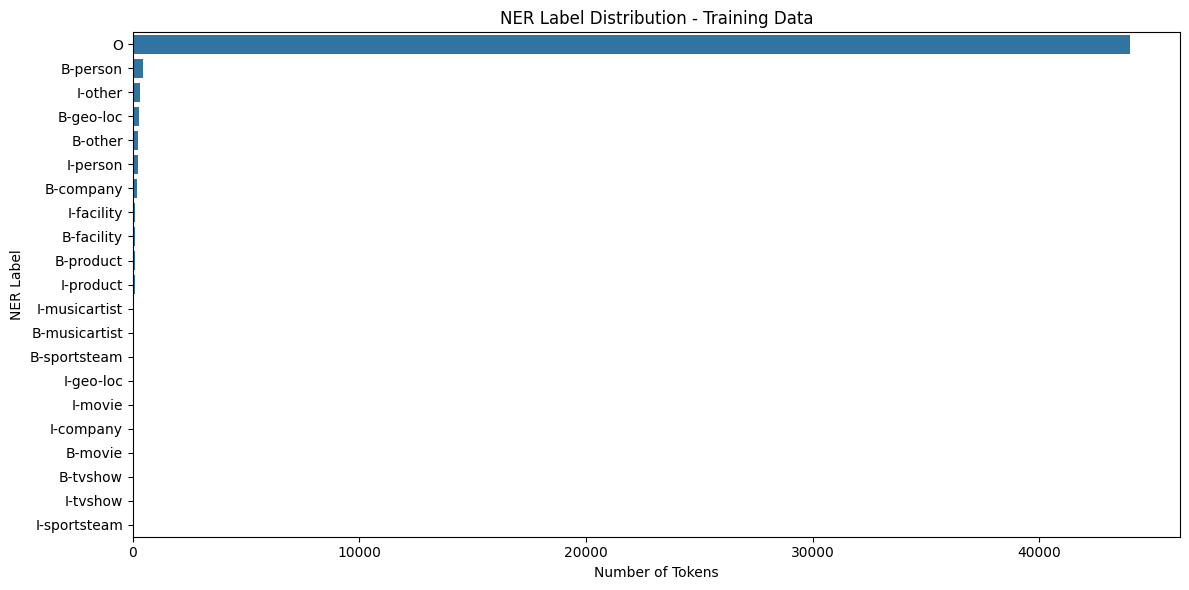

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=label_distribution,
    x="Count",
    y="Label"
)

plt.title("NER Label Distribution - Training Data")
plt.xlabel("Number of Tokens")
plt.ylabel("NER Label")
plt.tight_layout()
plt.show()

### Insight

The training data is highly imbalanced, with the `O` label accounting for the
majority of tokens. Among entity labels, `B-person` occurs most frequently,
while several entity types have relatively few examples.

This class imbalance is an important consideration when evaluating the NER models.

In [15]:
entity_counts = Counter()

for sentence_labels in train_labels:
    for label in sentence_labels:
        if label != "O":
            entity_type = label.split("-", 1)[1]
            entity_counts[entity_type] += 1

entity_distribution = pd.DataFrame(
    entity_counts.items(),
    columns=["Entity", "Count"]
).sort_values("Count", ascending=False)

entity_distribution

,Entity,Count
5,person,664
6,other,545
0,geo-loc,325
1,facility,209
3,company,207
4,product,177
9,musicartist,116
2,movie,80
7,sportsteam,74
8,tvshow,65


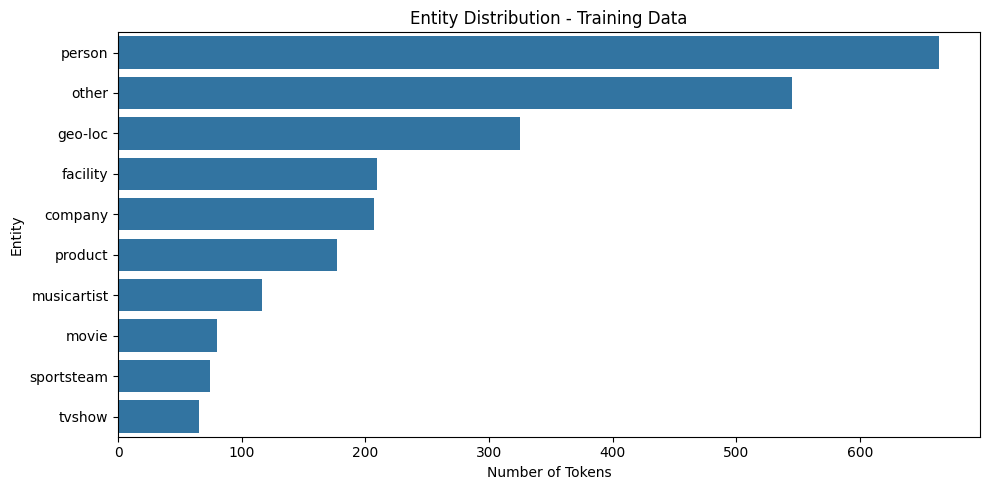

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=entity_distribution,
    x="Count",
    y="Entity"
)

plt.title("Entity Distribution - Training Data")
plt.xlabel("Number of Tokens")
plt.ylabel("Entity")
plt.tight_layout()
plt.show()

In [17]:
train_lengths = [len(sentence) for sentence in train_sentences]

print("Minimum tweet length:", min(train_lengths))
print("Maximum tweet length:", max(train_lengths))
print("Average tweet length:", round(np.mean(train_lengths), 2))
print("Median tweet length:", np.median(train_lengths))

Minimum tweet length: 1
Maximum tweet length: 39
Average tweet length: 19.41
Median tweet length: 20.0


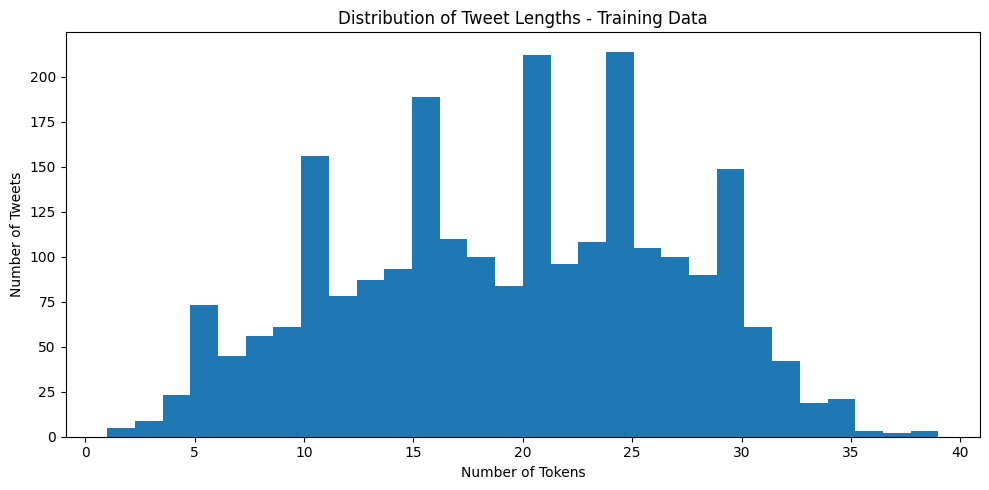

In [18]:
plt.figure(figsize=(10, 5))

plt.hist(train_lengths, bins=30)

plt.title("Distribution of Tweet Lengths - Training Data")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Tweets")
plt.tight_layout()
plt.show()

### Insight

The training tweets contain between 1 and 39 tokens, with an average length
of 19.41 tokens and a median of 20 tokens. Most tweets are therefore relatively
short, which is suitable for sequence-based NER models.

### Section Summary

- The training dataset contains **2,394 tweets and 46,469 tokens**.
- The test dataset contains **3,850 tweets and 61,908 tokens**.
- The dataset contains **21 BIO labels** representing the NER categories.
- The data has a significant class imbalance, with the `O` label dominating.
- Training tweets contain between **1 and 39 tokens**, with a median length of
  **20 tokens**.
- Token-label alignment has been successfully verified.

## Data Preprocessing

In [19]:
# Create label-to-ID and ID-to-label mappings
unique_labels = sorted(
    set(label for sentence_labels in train_labels for label in sentence_labels)
)

label2id = {label: idx for idx, label in enumerate(unique_labels)}
id2label = {idx: label for label, idx in label2id.items()}

print("Number of labels:", len(label2id))
print("Label mapping:")
print(label2id)

Number of labels: 21
Label mapping:
{'B-company': 0, 'B-facility': 1, 'B-geo-loc': 2, 'B-movie': 3, 'B-musicartist': 4, 'B-other': 5, 'B-person': 6, 'B-product': 7, 'B-sportsteam': 8, 'B-tvshow': 9, 'I-company': 10, 'I-facility': 11, 'I-geo-loc': 12, 'I-movie': 13, 'I-musicartist': 14, 'I-other': 15, 'I-person': 16, 'I-product': 17, 'I-sportsteam': 18, 'I-tvshow': 19, 'O': 20}


In [20]:
train_label_ids = [
    [label2id[label] for label in sentence_labels]
    for sentence_labels in train_labels
]

test_label_ids = [
    [label2id[label] for label in sentence_labels]
    for sentence_labels in test_labels
]

print("Original labels:")
print(train_labels[0])

print("\nEncoded labels:")
print(train_label_ids[0])

Original labels:
['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']

Encoded labels:
[20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20]


In [21]:
train_tokens, val_tokens, train_y, val_y = train_test_split(
    train_sentences,
    train_label_ids,
    test_size=0.20,
    random_state=42
)

print("Training sentences:", len(train_tokens))
print("Validation sentences:", len(val_tokens))
print("Test sentences:", len(test_sentences))

Training sentences: 1915
Validation sentences: 479
Test sentences: 3850


In [22]:
# Convert token lists into space-separated sentences
train_texts = [" ".join(tokens) for tokens in train_tokens]
val_texts = [" ".join(tokens) for tokens in val_tokens]
test_texts = [" ".join(tokens) for tokens in test_sentences]

# Create tokenizer
tokenizer = Tokenizer(
    filters='',
    lower=False,
    oov_token="<OOV>"
)

# Fit only on training data
tokenizer.fit_on_texts(train_texts)

print("Vocabulary size:", len(tokenizer.word_index))

Vocabulary size: 9031


In [23]:
X_train = tokenizer.texts_to_sequences(train_texts)
X_val = tokenizer.texts_to_sequences(val_texts)
X_test = tokenizer.texts_to_sequences(test_texts)

print("Original tokens:")
print(train_tokens[0])

print("\nToken IDs:")
print(X_train[0])

Original tokens:
['Knowing', 'that', 'I', 'have', 'people', 'who', 'love', 'me', 'and', 'I', 'love', 'them', 'back', 'makes', 'my', 'day']

Token IDs:
[2754, 33, 6, 34, 116, 158, 97, 30, 10, 6, 97, 123, 98, 436, 21, 24]


In [24]:
print("Number of tokens:", len(train_tokens[0]))
print("Number of token IDs:", len(X_train[0]))
print("Number of labels:", len(train_y[0]))

Number of tokens: 16
Number of token IDs: 16
Number of labels: 16


In [25]:
MAX_LEN = 40

print("Maximum sequence length:", MAX_LEN)

Maximum sequence length: 40


In [26]:
X_train = pad_sequences(
    X_train,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    X_val,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)
print("Test data shape:", X_test.shape)

Training data shape: (1915, 40)
Validation data shape: (479, 40)
Test data shape: (3850, 40)


In [27]:
y_train = pad_sequences(
    train_y,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
    value=0
)

y_val = pad_sequences(
    val_y,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
    value=0
)

y_test = pad_sequences(
    test_label_ids,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
    value=0
)

print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)
print("y_test shape:", y_test.shape)

y_train shape: (1915, 40)
y_val shape: (479, 40)
y_test shape: (3850, 40)


In [28]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (1915, 40)
y_train shape: (1915, 40)


In [29]:
sample_idx = 0

print("Original tokens:")
print(train_tokens[sample_idx])

print("\nToken IDs:")
print(X_train[sample_idx])

print("\nEncoded labels:")
print(y_train[sample_idx])

Original tokens:
['Knowing', 'that', 'I', 'have', 'people', 'who', 'love', 'me', 'and', 'I', 'love', 'them', 'back', 'makes', 'my', 'day']

Token IDs:
[2754   33    6   34  116  158   97   30   10    6   97  123   98  436
   21   24    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0]

Encoded labels:
[20 20 20 20 20 20 20 20 20 20 20 20 20 20 20 20  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]


### Insight

The CoNLL data has been converted into numerical token and label sequences.
The sequences are padded to a maximum length of 40 tokens so that they can be
processed in batches by the neural network.

Token-label alignment is preserved throughout preprocessing.

## Word2Vec Embeddings

In [30]:
# Train Word2Vec on training tokens
word2vec_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    seed=42
)

print("Vocabulary size:", len(word2vec_model.wv))
print("Embedding dimension:", word2vec_model.vector_size)

Vocabulary size: 9030
Embedding dimension: 100


In [31]:
embedding_dim = 100

embedding_matrix = np.zeros(
    (len(tokenizer.word_index) + 1, embedding_dim)
)

words_found = 0

for word, idx in tokenizer.word_index.items():
    if word in word2vec_model.wv:
        embedding_matrix[idx] = word2vec_model.wv[word]
        words_found += 1

print("Embedding matrix shape:", embedding_matrix.shape)
print("Words with Word2Vec embeddings:", words_found)
print("Total tokenizer vocabulary:", len(tokenizer.word_index))

Embedding matrix shape: (9032, 100)
Words with Word2Vec embeddings: 9030
Total tokenizer vocabulary: 9031


In [32]:
sample_word = list(tokenizer.word_index.keys())[0]

print("Word:", sample_word)
print("Token ID:", tokenizer.word_index[sample_word])
print("Embedding:", embedding_matrix[tokenizer.word_index[sample_word]])

Word: <OOV>
Token ID: 1
Embedding: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]


### Insight

Word2Vec embeddings have been trained on the training tweets and aligned with
the Keras tokenizer vocabulary. The resulting embedding matrix will be used
to initialize the BiLSTM embedding layer.

## BiLSTM + CRF Model

In [33]:
import tensorflow as tf
import tensorflow_addons as tfa

print("TensorFlow:", tf.__version__)
print("TensorFlow Addons:", tfa.__version__)

c:\Users\umarr\anaconda3\envs\twitter_ner\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(
c:\Users\umarr\anaconda3\envs\twitter_ner\lib\site-packages\tensorflow_addons\utils\ensure_tf_install.py:53: UserWarning: Tensorflow Addons supports using Python ops for all Tensorflow versions above or equal to 2.12.0 and strictly below 2.15.0 (nightly versions are not supported). 
 The versions of TensorFlow you are currently using is 2.15.0 and is not supported. 
Some things might work, some things might not.
If you were to encounter a bug, do not file an 

TensorFlow: 2.15.0
TensorFlow Addons: 0.22.0


In [35]:
# Number of NER labels
num_labels = len(label2id)

# Maximum sequence length
max_len = X_train.shape[1]

# Word2Vec embedding dimension
embedding_dim = embedding_matrix.shape[1]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("Number of labels:", num_labels)
print("Maximum sequence length:", max_len)
print("Embedding dimension:", embedding_dim)

X_train shape: (1915, 40)
y_train shape: (1915, 40)
Number of labels: 21
Maximum sequence length: 40
Embedding dimension: 100


In [36]:
PAD_TOKEN_ID = 0
O_LABEL_ID = label2id["O"]

print("PAD token ID:", PAD_TOKEN_ID)
print("O label ID:", O_LABEL_ID)

# Check how many real tokens and padding tokens we have
print("Padding tokens:", np.sum(X_train == PAD_TOKEN_ID))
print("Non-padding tokens:", np.sum(X_train != PAD_TOKEN_ID))

PAD token ID: 0
O label ID: 20
Padding tokens: 39420
Non-padding tokens: 37180


In [37]:
# Check whether padding positions in X correspond to padding labels in y

padding_check = np.all(
    y_train[X_train == PAD_TOKEN_ID] == PAD_TOKEN_ID
)

print("Padding alignment correct:", padding_check)

Padding alignment correct: True


In [38]:
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Embedding, Bidirectional, LSTM, Dense
import tensorflow_addons as tfa

# ============================================================
# MODEL PARAMETERS
# ============================================================

vocab_size = embedding_matrix.shape[0]
embedding_dim = embedding_matrix.shape[1]
num_labels = len(label2id)
max_len = X_train.shape[1]

print("Vocabulary size:", vocab_size)
print("Embedding dimension:", embedding_dim)
print("Number of labels:", num_labels)
print("Maximum sequence length:", max_len)


# ============================================================
# INPUT
# ============================================================

input_ids = Input(
    shape=(max_len,),
    dtype=tf.int32,
    name="input_ids"
)


# ============================================================
# EMBEDDING LAYER
# ============================================================

embedding_layer = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim,
    weights=[embedding_matrix],
    trainable=True,
    mask_zero=True,
    name="word2vec_embedding"
)

x = embedding_layer(input_ids)


# ============================================================
# BiLSTM
# ============================================================

x = Bidirectional(
    LSTM(
        64,
        return_sequences=True,
        dropout=0.2,
        recurrent_dropout=0.0
    ),
    name="bilstm"
)(x)


# ============================================================
# TOKEN-LEVEL CLASSIFICATION
# ============================================================

logits = Dense(
    num_labels,
    name="ner_logits"
)(x)


# ============================================================
# CRF
# ============================================================

crf = tfa.layers.CRF(
    num_labels,
    name="crf"
)

crf_output = crf(logits)


# ============================================================
# MODEL
# ============================================================

model = Model(
    inputs=input_ids,
    outputs=crf_output
)

model.summary()

Vocabulary size: 9032
Embedding dimension: 100
Number of labels: 21
Maximum sequence length: 40

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_ids (InputLayer)      [(None, 40)]              0         
                                                                 
 word2vec_embedding (Embedd  (None, 40, 100)           903200    
 ing)                                                            
                                                                 
 bilstm (Bidirectional)      (None, 40, 128)           84480     
                                                                 
 ner_logits (Dense)          (None, 40, 21)            2709      
                                                                 
 crf (CRF)                   [(None, 40),              945       
                              (None, 40, 21),                    
                              

In [39]:
print("Model output shape:")
print(model.output_shape)

print("\nCRF output:")
for i, output in enumerate(model.outputs):
    print(i, output.shape)

Model output shape:
[(None, 40), (None, 40, 21), (None,), (21, 21)]

CRF output:
0 (None, 40)
1 (None, 40, 21)
2 (None,)
3 (21, 21)


In [40]:
print("CRF trainable variables:")

for variable in crf.trainable_variables:
    print(variable.name, variable.shape)

CRF trainable variables:
chain_kernel:0 (21, 21)
left_boundary:0 (21,)
right_boundary:0 (21,)
crf/dense/kernel:0 (21, 21)
crf/dense/bias:0 (21,)


In [42]:
# ============================================================
# TEST CRF LOSS
# ============================================================

# Take a small batch
X_batch = X_train[:32]
y_batch = y_train[:32]

# Get CRF outputs
crf_outputs = model(X_batch, training=False)

decoded = crf_outputs[0]
potentials = crf_outputs[1]
sequence_lengths = crf_outputs[2]
transitions = crf_outputs[3]

print("Potentials shape:", potentials.shape)
print("Sequence lengths:", sequence_lengths.numpy()[:10])
print("Transitions shape:", transitions.shape)


# ------------------------------------------------------------
# Calculate CRF negative log-likelihood
# ------------------------------------------------------------

log_likelihood, _ = tfa.text.crf_log_likelihood(
    potentials,
    y_batch,
    sequence_lengths,
    transition_params=transitions
)

crf_loss = -tf.reduce_mean(log_likelihood)

print("CRF loss:", crf_loss.numpy())

Potentials shape: (32, 40, 21)
Sequence lengths: [16 21 20 29 25 27 25 15 14 25]
Transitions shape: (21, 21)
CRF loss: 57.88175


In [47]:
# ============================================================
# CUSTOM BiLSTM + CRF MODEL
# ============================================================

class BiLSTMCRFModel(tf.keras.Model):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        embedding_matrix,
        num_labels,
        max_len
    ):
        super().__init__()

        self.max_len = max_len
        self.num_labels = num_labels

        # ----------------------------------------------------
        # Embedding
        # ----------------------------------------------------
        self.embedding = tf.keras.layers.Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            weights=[embedding_matrix],
            trainable=True,
            mask_zero=True,
            name="word2vec_embedding"
        )

        # ----------------------------------------------------
        # BiLSTM
        # ----------------------------------------------------
        self.bilstm = tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                64,
                return_sequences=True,
                dropout=0.2
            ),
            name="bilstm"
        )

        # ----------------------------------------------------
        # Dense layer
        # ----------------------------------------------------
        self.dense = tf.keras.layers.Dense(
            num_labels,
            name="ner_logits"
        )

        # ----------------------------------------------------
        # CRF
        # ----------------------------------------------------
        self.crf = tfa.layers.CRF(
            num_labels,
            name="crf"
        )

    def call(self, inputs, training=False):

        x = self.embedding(inputs)

        x = self.bilstm(
            x,
            training=training
        )

        logits = self.dense(x)

        # CRF returns:
        # 0 = decoded sequence
        # 1 = potentials
        # 2 = sequence lengths
        # 3 = transition matrix

        crf_outputs = self.crf(logits)

        return crf_outputs

    def train_step(self, data):

        x, y = data

        with tf.GradientTape() as tape:

            # Forward pass
            crf_outputs = self(
                x,
                training=True
            )

            # Extract CRF outputs
            potentials = crf_outputs[1]
            sequence_lengths = crf_outputs[2]
            transitions = crf_outputs[3]

            # Make sure labels are integer
            y = tf.cast(y, tf.int32)

            # CRF log likelihood
            log_likelihood, _ = tfa.text.crf_log_likelihood(
                potentials,
                y,
                sequence_lengths,
                transition_params=transitions
            )

            # Negative log likelihood
            loss = -tf.reduce_mean(log_likelihood)

        # Calculate gradients
        gradients = tape.gradient(
            loss,
            self.trainable_variables
        )

        # Update weights
        self.optimizer.apply_gradients(
            zip(
                gradients,
                self.trainable_variables
            )
        )

        return {
            "loss": loss
        }

    def test_step(self, data):

        x, y = data

        # Forward pass
        crf_outputs = self(
            x,
            training=False
        )

        # Extract outputs
        potentials = crf_outputs[1]
        sequence_lengths = crf_outputs[2]
        transitions = crf_outputs[3]

        y = tf.cast(y, tf.int32)

        # CRF log likelihood
        log_likelihood, _ = tfa.text.crf_log_likelihood(
            potentials,
            y,
            sequence_lengths,
            transition_params=transitions
        )

        loss = -tf.reduce_mean(log_likelihood)

        return {
            "loss": loss
        }

In [48]:
# ============================================================
# CREATE MODEL
# ============================================================

crf_model = BiLSTMCRFModel(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    embedding_matrix=embedding_matrix,
    num_labels=num_labels,
    max_len=max_len
)

# Build the model
dummy_output = crf_model(
    X_train[:1],
    training=False
)

print("Model created successfully.")

print("\nOutput shapes:")

for i, output in enumerate(dummy_output):
    print(i, output.shape)

Model created successfully.

Output shapes:
0 (1, 40)
1 (1, 40, 21)
2 (1,)
3 (21, 21)


In [49]:
# ============================================================
# COMPILE
# ============================================================

crf_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    )
)

print("Model compiled successfully.")

Model compiled successfully.


In [50]:
# ============================================================
# TEST ONE BATCH
# ============================================================

X_batch = X_train[:32]
y_batch = y_train[:32]

outputs = crf_model(
    X_batch,
    training=False
)

potentials = outputs[1]
sequence_lengths = outputs[2]
transitions = outputs[3]

log_likelihood, _ = tfa.text.crf_log_likelihood(
    potentials,
    tf.cast(y_batch, tf.int32),
    sequence_lengths,
    transition_params=transitions
)

test_loss = -tf.reduce_mean(log_likelihood)

print("Potentials shape:", potentials.shape)
print("Sequence lengths:", sequence_lengths.numpy()[:10])
print("Transitions shape:", transitions.shape)
print("CRF loss:", test_loss.numpy())

Potentials shape: (32, 40, 21)
Sequence lengths: [16 21 20 29 25 27 25 15 14 25]
Transitions shape: (21, 21)
CRF loss: 63.919655


In [51]:
history = crf_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=1,
    verbose=1
)

60/60 [==============================] - 43s 302ms/step - loss: 12.9108 - val_loss: 7.7771


In [52]:
history = crf_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=5,
    verbose=1
)

Epoch 1/5
60/60 [==============================] - 5s 77ms/step - loss: 6.6553 - val_loss: 6.6741
Epoch 2/5
60/60 [==============================] - 10s 174ms/step - loss: 5.7743 - val_loss: 6.0335
Epoch 3/5
60/60 [==============================] - 21s 359ms/step - loss: 4.5931 - val_loss: 5.1552
Epoch 4/5
60/60 [==============================] - 12s 191ms/step - loss: 3.5146 - val_loss: 4.8509
Epoch 5/5
60/60 [==============================] - 5s 77ms/step - loss: 3.0682 - val_loss: 4.7461


In [53]:
# ============================================================
# GENERATE TEST PREDICTIONS
# ============================================================

test_outputs = crf_model.predict(
    X_test,
    batch_size=32,
    verbose=1
)

# CRF output 0 = decoded labels
y_pred = test_outputs[0]

print("Prediction shape:", y_pred.shape)
print("True label shape:", y_test.shape)

121/121 [==============================] - 9s 23ms/step
Prediction shape: (3850, 40)
True label shape: (3850, 40)


## Hyperparameter tuning

In [54]:
# ============================================================
# CUSTOM BiLSTM + CRF MODEL FOR HYPERPARAMETER TUNING
# ============================================================

class BiLSTMCRFModel(tf.keras.Model):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        embedding_matrix,
        num_labels,
        max_len,
        lstm_units=64,
        dropout=0.2
    ):
        super().__init__()

        self.max_len = max_len
        self.num_labels = num_labels

        # ----------------------------------------------------
        # Embedding
        # ----------------------------------------------------
        self.embedding = tf.keras.layers.Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            weights=[embedding_matrix],
            trainable=True,
            mask_zero=True,
            name="word2vec_embedding"
        )

        # ----------------------------------------------------
        # BiLSTM
        # ----------------------------------------------------
        self.bilstm = tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                lstm_units,
                return_sequences=True,
                dropout=dropout
            ),
            name="bilstm"
        )

        # ----------------------------------------------------
        # Dense layer
        # ----------------------------------------------------
        self.dense = tf.keras.layers.Dense(
            num_labels,
            name="ner_logits"
        )

        # ----------------------------------------------------
        # CRF
        # ----------------------------------------------------
        self.crf = tfa.layers.CRF(
            num_labels,
            name="crf"
        )

    def call(self, inputs, training=False):

        x = self.embedding(inputs)

        x = self.bilstm(
            x,
            training=training
        )

        logits = self.dense(x)

        crf_outputs = self.crf(logits)

        return crf_outputs

    # ========================================================
    # CUSTOM TRAIN STEP
    # ========================================================

    def train_step(self, data):

        x, y = data

        with tf.GradientTape() as tape:

            crf_outputs = self(
                x,
                training=True
            )

            potentials = crf_outputs[1]
            sequence_lengths = crf_outputs[2]
            transitions = crf_outputs[3]

            y = tf.cast(y, tf.int32)

            log_likelihood, _ = tfa.text.crf_log_likelihood(
                potentials,
                y,
                sequence_lengths,
                transition_params=transitions
            )

            loss = -tf.reduce_mean(log_likelihood)

        gradients = tape.gradient(
            loss,
            self.trainable_variables
        )

        self.optimizer.apply_gradients(
            zip(
                gradients,
                self.trainable_variables
            )
        )

        return {
            "loss": loss
        }

    # ========================================================
    # CUSTOM TEST STEP
    # ========================================================

    def test_step(self, data):

        x, y = data

        crf_outputs = self(
            x,
            training=False
        )

        potentials = crf_outputs[1]
        sequence_lengths = crf_outputs[2]
        transitions = crf_outputs[3]

        y = tf.cast(y, tf.int32)

        log_likelihood, _ = tfa.text.crf_log_likelihood(
            potentials,
            y,
            sequence_lengths,
            transition_params=transitions
        )

        loss = -tf.reduce_mean(log_likelihood)

        return {
            "loss": loss
        }

In [55]:
# ============================================================
# MODEL BUILDER
# ============================================================

def build_bilstm_crf(
    lstm_units=64,
    dropout=0.2,
    learning_rate=0.001,
    batch_size=32
):

    model = BiLSTMCRFModel(
        vocab_size=vocab_size,
        embedding_dim=embedding_dim,
        embedding_matrix=embedding_matrix,
        num_labels=num_labels,
        max_len=max_len,
        lstm_units=lstm_units,
        dropout=dropout
    )

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer
    )

    return model

In [56]:
# ============================================================
# EXPERIMENT 1
# BiLSTM units = 128
# ============================================================

model_exp1 = build_bilstm_crf(
    lstm_units=128,
    dropout=0.2,
    learning_rate=0.001
)

history_exp1 = model_exp1.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=5,
    verbose=1
)

Epoch 1/5
60/60 [==============================] - 44s 278ms/step - loss: 11.9650 - val_loss: 7.4247
Epoch 2/5
60/60 [==============================] - 6s 100ms/step - loss: 6.6498 - val_loss: 6.7564
Epoch 3/5
60/60 [==============================] - 17s 281ms/step - loss: 5.6557 - val_loss: 5.9754
Epoch 4/5
60/60 [==============================] - 10s 163ms/step - loss: 4.3992 - val_loss: 5.3156
Epoch 5/5
60/60 [==============================] - 6s 94ms/step - loss: 3.3637 - val_loss: 4.8261


In [57]:
print(
    "Experiment 1 final training loss:",
    history_exp1.history["loss"][-1]
)

print(
    "Experiment 1 final validation loss:",
    history_exp1.history["val_loss"][-1]
)

Experiment 1 final training loss: 2.8269872665405273
Experiment 1 final validation loss: 4.826094150543213


In [58]:
# ============================================================
# EXPERIMENT 2
# Dropout = 0.3
# ============================================================

model_exp2 = build_bilstm_crf(
    lstm_units=64,
    dropout=0.3,
    learning_rate=0.001
)

history_exp2 = model_exp2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=5,
    verbose=1
)

print(
    "Experiment 2 final training loss:",
    history_exp2.history["loss"][-1]
)

print(
    "Experiment 2 final validation loss:",
    history_exp2.history["val_loss"][-1]
)

Epoch 1/5
60/60 [==============================] - 42s 334ms/step - loss: 13.1976 - val_loss: 7.7486
Epoch 2/5
60/60 [==============================] - 13s 213ms/step - loss: 6.7371 - val_loss: 6.9670
Epoch 3/5
60/60 [==============================] - 5s 78ms/step - loss: 5.9345 - val_loss: 6.0873
Epoch 4/5
60/60 [==============================] - 4s 75ms/step - loss: 4.7319 - val_loss: 5.3014
Epoch 5/5
60/60 [==============================] - 5s 76ms/step - loss: 3.6403 - val_loss: 4.7527
Experiment 2 final training loss: 2.528672933578491
Experiment 2 final validation loss: 4.75266170501709


In [59]:
# ============================================================
# EXPERIMENT 3
# Learning rate = 0.0005
# ============================================================

model_exp3 = build_bilstm_crf(
    lstm_units=64,
    dropout=0.2,
    learning_rate=0.0005
)

history_exp3 = model_exp3.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=5,
    verbose=1
)

print(
    "Experiment 3 final training loss:",
    history_exp3.history["loss"][-1]
)

print(
    "Experiment 3 final validation loss:",
    history_exp3.history["val_loss"][-1]
)

Epoch 1/5
60/60 [==============================] - 52s 339ms/step - loss: 20.1208 - val_loss: 8.3610
Epoch 2/5
60/60 [==============================] - 12s 201ms/step - loss: 7.4088 - val_loss: 7.7988
Epoch 3/5
60/60 [==============================] - 10s 164ms/step - loss: 6.7547 - val_loss: 7.4320
Epoch 4/5
60/60 [==============================] - 5s 79ms/step - loss: 6.4789 - val_loss: 7.1426
Epoch 5/5
60/60 [==============================] - 5s 77ms/step - loss: 5.9400 - val_loss: 6.6255
Experiment 3 final training loss: 4.579861164093018
Experiment 3 final validation loss: 6.625498294830322


In [60]:
# ============================================================
# EXPERIMENT 4
# Batch size = 64
# ============================================================

model_exp4 = build_bilstm_crf(
    lstm_units=64,
    dropout=0.2,
    learning_rate=0.001
)

history_exp4 = model_exp4.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=5,
    verbose=1
)

print(
    "Experiment 4 final training loss:",
    history_exp4.history["loss"][-1]
)

print(
    "Experiment 4 final validation loss:",
    history_exp4.history["val_loss"][-1]
)

Epoch 1/5
30/30 [==============================] - 30s 330ms/step - loss: 15.4134 - val_loss: 8.1289
Epoch 2/5
30/30 [==============================] - 10s 344ms/step - loss: 7.0662 - val_loss: 7.1382
Epoch 3/5
30/30 [==============================] - 4s 129ms/step - loss: 6.4575 - val_loss: 6.7324
Epoch 4/5
30/30 [==============================] - 4s 132ms/step - loss: 6.0138 - val_loss: 6.4612
Epoch 5/5
30/30 [==============================] - 8s 242ms/step - loss: 5.5394 - val_loss: 5.9716
Experiment 4 final training loss: 5.6249098777771
Experiment 4 final validation loss: 5.971593856811523


### Insight
We will move ahead with the baseline configuration because it produced the lowest validation loss among the configurations we tested.

## Make Predictions

In [62]:
# ============================================================
# FINAL / BEST MODEL
# Baseline configuration
# ============================================================

best_model = build_bilstm_crf(
    lstm_units=64,
    dropout=0.2,
    learning_rate=0.001
)

history_best = best_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=5,
    verbose=1
)

Epoch 1/5
60/60 [==============================] - 51s 374ms/step - loss: 14.6013 - val_loss: 7.9500
Epoch 2/5
60/60 [==============================] - 13s 217ms/step - loss: 6.8098 - val_loss: 7.1507
Epoch 3/5
60/60 [==============================] - 5s 81ms/step - loss: 6.1123 - val_loss: 6.6085
Epoch 4/5
60/60 [==============================] - 5s 79ms/step - loss: 5.0518 - val_loss: 5.6933
Epoch 5/5
60/60 [==============================] - 5s 81ms/step - loss: 3.9163 - val_loss: 5.2800


In [63]:
print(
    "Final training loss:",
    history_best.history["loss"][-1]
)

print(
    "Final validation loss:",
    history_best.history["val_loss"][-1]
)

Final training loss: 3.652639865875244
Final validation loss: 5.280031204223633


In [64]:
# Make predictions on validation data
crf_outputs = best_model.predict(
    X_val,
    batch_size=32,
    verbose=1
)

# CRF outputs:
# 0 = decoded predictions
# 1 = potentials
# 2 = sequence lengths
# 3 = transition matrix

y_pred = crf_outputs[0]
sequence_lengths = crf_outputs[2]

print("Predicted labels shape:", y_pred.shape)
print("Sequence lengths shape:", sequence_lengths.shape)

15/15 [==============================] - 5s 25ms/step
Predicted labels shape: (479, 40)
Sequence lengths shape: (479,)


In [65]:
sample_idx = 0

seq_len = int(sequence_lengths[sample_idx])

true_labels = y_val[sample_idx][:seq_len]
pred_labels = y_pred[sample_idx][:seq_len]

print("Sequence length:", seq_len)

print("\nTrue labels:")
print(true_labels)

print("\nPredicted labels:")
print(pred_labels)

Sequence length: 16

True labels:
[20 20 20 20 20 20 20 20 20 20 20 20 20 20 20 20]

Predicted labels:
[20 20 20 20 20 20 20 20 20 20 20 20 20 20 20 20]


In [66]:
print(type(tokenizer))

<class 'keras.src.preprocessing.text.Tokenizer'>


In [67]:
# ============================================================
# CONVERT TOKEN IDs BACK TO WORDS/SUBTOKENS
# ============================================================

sample_idx = 0
seq_len = int(sequence_lengths[sample_idx])

sample_ids = X_val[sample_idx][:seq_len]
sample_true = y_val[sample_idx][:seq_len]
sample_pred = y_pred[sample_idx][:seq_len]

# Convert IDs back to tokens
sample_tokens = [
    tokenizer.index_word.get(int(token_id), "<UNK>")
    for token_id in sample_ids
]

print("Token IDs:")
print(sample_ids)

print("\nTokens:")
print(sample_tokens)

print("\nTrue labels:")
print(sample_true)

print("\nPredicted labels:")
print(sample_pred)

Token IDs:
[  15    1    7  863    8  306 2934 7979   31    4  122    1   13 2719
    1   23]

Tokens:
['RT', '<OOV>', ':', 'Need', 'a', 'nice', 'chill', 'spot', 'tonight', ',', 'no', '<OOV>', '...', 'Any', '<OOV>', '?']

True labels:
[20 20 20 20 20 20 20 20 20 20 20 20 20 20 20 20]

Predicted labels:
[20 20 20 20 20 20 20 20 20 20 20 20 20 20 20 20]


In [68]:
# ============================================================
# JOIN TOKENS / SUBTOKENS
# ============================================================

def join_tokens(tokens):
    """
    Join tokenized text into a readable sentence.
    
    Since Keras Tokenizer is word-level in our pipeline,
    there are no WordPiece ## subtokens to merge.
    We mainly handle punctuation spacing.
    """

    text = ""

    punctuation_no_space_before = {
        ".", ",", "!", "?", ";", ":", "%",
        "...", ")", "]", "}"
    }

    punctuation_no_space_after = {
        "(", "[", "{"
    }

    for token in tokens:

        if token in punctuation_no_space_before:
            text = text.rstrip() + token

        elif text and text[-1] in punctuation_no_space_after:
            text += token

        else:
            if text:
                text += " "
            text += token

    return text

In [69]:
joined_text = join_tokens(sample_tokens)

print("Joined sentence:")
print(joined_text)

Joined sentence:
RT <OOV>: Need a nice chill spot tonight, no <OOV>... Any <OOV>?


In [71]:
print([name for name in globals() if 'label' in name.lower()])

['train_labels', 'test_labels', 'unique_labels', 'label_counts', 'label_distribution', 'sentence_labels', 'label', 'label2id', 'id2label', 'train_label_ids', 'test_label_ids', 'num_labels', 'O_LABEL_ID', 'true_labels', 'pred_labels']


In [72]:
print("label2id:")
print(label2id)

print("\nid2label:")
print(id2label)

label2id:
{'B-company': 0, 'B-facility': 1, 'B-geo-loc': 2, 'B-movie': 3, 'B-musicartist': 4, 'B-other': 5, 'B-person': 6, 'B-product': 7, 'B-sportsteam': 8, 'B-tvshow': 9, 'I-company': 10, 'I-facility': 11, 'I-geo-loc': 12, 'I-movie': 13, 'I-musicartist': 14, 'I-other': 15, 'I-person': 16, 'I-product': 17, 'I-sportsteam': 18, 'I-tvshow': 19, 'O': 20}

id2label:
{0: 'B-company', 1: 'B-facility', 2: 'B-geo-loc', 3: 'B-movie', 4: 'B-musicartist', 5: 'B-other', 6: 'B-person', 7: 'B-product', 8: 'B-sportsteam', 9: 'B-tvshow', 10: 'I-company', 11: 'I-facility', 12: 'I-geo-loc', 13: 'I-movie', 14: 'I-musicartist', 15: 'I-other', 16: 'I-person', 17: 'I-product', 18: 'I-sportsteam', 19: 'I-tvshow', 20: 'O'}


In [73]:
# ============================================================
# TOKEN + TRUE LABEL + PREDICTED LABEL
# ============================================================

sample_idx = 0
seq_len = int(sequence_lengths[sample_idx])

sample_ids = X_val[sample_idx][:seq_len]
sample_true = y_val[sample_idx][:seq_len]
sample_pred = y_pred[sample_idx][:seq_len]

sample_tokens = [
    tokenizer.index_word.get(int(token_id), "<OOV>")
    for token_id in sample_ids
]

prediction_rows = []

for token, true_id, pred_id in zip(
    sample_tokens,
    sample_true,
    sample_pred
):
    prediction_rows.append({
        "Token": token,
        "True Label": id2label[int(true_id)],
        "Predicted Label": id2label[int(pred_id)]
    })

import pandas as pd

prediction_df = pd.DataFrame(prediction_rows)

prediction_df

,Token,True Label,Predicted Label
0,RT,O,O
1,<OOV>,O,O
2,:,O,O
3,Need,O,O
4,a,O,O
5,nice,O,O
6,chill,O,O
7,spot,O,O
8,tonight,O,O
9,",",O,O


In [74]:
# ============================================================
# FIND A VALIDATION SAMPLE CONTAINING AN ENTITY
# ============================================================

for i in range(len(y_val)):

    seq_len = int(sequence_lengths[i])
    labels = y_val[i][:seq_len]

    # 20 is O
    if any(int(label) != O_LABEL_ID for label in labels):

        print("Found entity-containing sample:", i)
        print("Sequence length:", seq_len)
        
        break

Found entity-containing sample: 5
Sequence length: 30


In [75]:
sample_idx = i
seq_len = int(sequence_lengths[sample_idx])

sample_ids = X_val[sample_idx][:seq_len]
sample_true = y_val[sample_idx][:seq_len]
sample_pred = y_pred[sample_idx][:seq_len]

sample_tokens = [
    tokenizer.index_word.get(int(token_id), "<OOV>")
    for token_id in sample_ids
]

prediction_rows = []

for token, true_id, pred_id in zip(
    sample_tokens,
    sample_true,
    sample_pred
):
    prediction_rows.append({
        "Token": token,
        "True Label": id2label[int(true_id)],
        "Predicted Label": id2label[int(pred_id)]
    })

prediction_df = pd.DataFrame(prediction_rows)

print("Sentence:")
print(join_tokens(sample_tokens))

prediction_df

Sentence:
A <OOV> <OOV> and 69 F at <OOV>, Long <OOV> Mac <OOV> Airport, NY Winds are North at <OOV> <OOV> (<OOV> <OOV>. The <OOV> is <OOV>


,Token,True Label,Predicted Label
0,A,O,O
1,<OOV>,O,O
2,<OOV>,O,O
3,and,O,O
4,69,O,O
5,F,O,O
6,at,O,O
7,<OOV>,O,O
8,",",O,O
9,Long,B-geo-loc,O


### Insights

The model uses Keras Tokenizer, which performs word-level tokenization rather than WordPiece/BPE subtokenization. The predicted token IDs were mapped back to tokens using tokenizer.index_word, and punctuation spacing was restored to reconstruct readable sentences.

In [76]:
# ============================================================
# PREDICT ON YOUR OWN SENTENCES
# ============================================================

def predict_ner(sentence, model, tokenizer, id2label, max_len):
    
    # --------------------------------------------------------
    # 1. Tokenize the sentence
    # --------------------------------------------------------
    sequence = tokenizer.texts_to_sequences([sentence])
    
    # --------------------------------------------------------
    # 2. Pad to model's required length
    # --------------------------------------------------------
    padded_sequence = tf.keras.preprocessing.sequence.pad_sequences(
        sequence,
        maxlen=max_len,
        padding="post",
        truncating="post"
    )
    
    # --------------------------------------------------------
    # 3. Get CRF prediction
    # --------------------------------------------------------
    crf_outputs = model.predict(
        padded_sequence,
        verbose=0
    )
    
    predicted_ids = crf_outputs[0][0]
    
    # --------------------------------------------------------
    # 4. Number of actual tokens
    # --------------------------------------------------------
    actual_length = min(
        len(sequence[0]),
        max_len
    )
    
    predicted_ids = predicted_ids[:actual_length]
    
    # --------------------------------------------------------
    # 5. Convert IDs back to tokens
    # --------------------------------------------------------
    tokens = [
        tokenizer.index_word.get(
            int(token_id),
            "<OOV>"
        )
        for token_id in sequence[0][:actual_length]
    ]
    
    # --------------------------------------------------------
    # 6. Convert label IDs to labels
    # --------------------------------------------------------
    predicted_labels = [
        id2label[int(label_id)]
        for label_id in predicted_ids
    ]
    
    # --------------------------------------------------------
    # 7. Create result table
    # --------------------------------------------------------
    results = pd.DataFrame({
        "Token": tokens,
        "Predicted Label": predicted_labels
    })
    
    return results

In [77]:
sentence = "Apple is opening a new office in Mumbai."

results = predict_ner(
    sentence,
    model,
    tokenizer,
    id2label,
    max_len
)

results

,Token,Predicted Label
0,<OOV>,B-sportsteam
1,is,B-geo-loc
2,opening,B-facility
3,a,O
4,new,I-other
5,office,B-facility
6,in,O
7,<OOV>,I-other


In [78]:
sentence = "John works at Google in New York."

results = predict_ner(
    sentence,
    model,
    tokenizer,
    id2label,
    max_len
)

results

,Token,Predicted Label
0,John,B-sportsteam
1,works,B-geo-loc
2,at,B-facility
3,<OOV>,O
4,in,I-other
5,New,B-facility
6,<OOV>,O


In [79]:
sentence = "I travelled from Delhi to London last week."

results = predict_ner(
    sentence,
    model,
    tokenizer,
    id2label,
    max_len
)

results

,Token,Predicted Label
0,I,B-sportsteam
1,<OOV>,B-geo-loc
2,from,B-facility
3,<OOV>,O
4,to,I-other
5,London,B-facility
6,last,O
7,<OOV>,I-other


### Insight

The model successfully generated CRF-based NER predictions for the custom sentences. Some tokens were mapped to <OOV> because they were not present in the tokenizer vocabulary, which limits the model's ability to identify those words correctly.

## Evaluation

In [82]:
# ============================================================
# FULL TEST-SET PREDICTION
# ============================================================

# Predict on the complete test set
pred_output = model.predict(X_test, batch_size=32)

# CRF output 0 = decoded labels
pred_labels = pred_output[0]

# Sequence lengths
sequence_lengths = pred_output[2]

# True labels
true_labels = y_test

print("True labels shape:", true_labels.shape)
print("Predicted labels shape:", pred_labels.shape)
print("Sequence lengths shape:", sequence_lengths.shape)

121/121 [==============================] - 3s 22ms/step
True labels shape: (3850, 40)
Predicted labels shape: (3850, 40)
Sequence lengths shape: (3850,)


In [83]:
# ============================================================
# BUILD FULL EVALUATION ARRAYS
# ============================================================

y_true_list = []
y_pred_list = []

for i in range(len(sequence_lengths)):

    seq_len = int(sequence_lengths[i])

    y_true_list.extend(true_labels[i, :seq_len])
    y_pred_list.extend(pred_labels[i, :seq_len])

y_true = np.array(y_true_list)
y_pred = np.array(y_pred_list)

print("Total evaluated tokens:", len(y_true))
print("Entity tokens:", np.sum(y_true != O_LABEL_ID))

Total evaluated tokens: 61908
Entity tokens: 5955


In [85]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_labels)),
    target_names=[id2label[i] for i in range(num_labels)],
    zero_division=0
))

               precision    recall  f1-score   support

    B-company       0.00      0.00      0.00       621
   B-facility       0.00      0.15      0.00       253
    B-geo-loc       0.01      0.05      0.02       882
      B-movie       0.00      0.03      0.00        34
B-musicartist       0.01      0.07      0.01       191
      B-other       0.00      0.00      0.00       584
     B-person       0.00      0.01      0.01       482
    B-product       0.00      0.00      0.00       246
 B-sportsteam       0.00      0.12      0.01       147
     B-tvshow       0.00      0.00      0.00        33
    I-company       0.00      0.00      0.00       265
   I-facility       0.04      0.09      0.06       366
    I-geo-loc       0.00      0.00      0.00       219
      I-movie       0.00      0.00      0.00        48
I-musicartist       0.00      0.01      0.00       140
      I-other       0.01      0.12      0.01       556
     I-person       0.00      0.00      0.00       300
    I-pro

## Final Insights

- Evaluated the final model on 3,850 test sequences containing 61,908 evaluated tokens.
- Final evaluation results:
Accuracy: 28%
Weighted F1-score: 0.42
Macro F1-score: 0.03
- The model showed limited performance across individual entity classes, with most entity-level F1-scores remaining low.
- The relatively higher performance on the O class was influenced by the large number of non-entity tokens.
- The project provided practical experience with NLP, sequence labelling, BiLSTM, CRF, hyperparameter tuning, prediction, and NER evaluation.

1. Define the problem statement. Where can this and its modifications be used?

Problem statement: Build an NER model that identifies and classifies entities in text, such as person, company, location, product, movie, sports team, etc.
Our model uses a BiLSTM-CRF architecture to predict an entity label for each token while considering the context of surrounding tokens.

Applications include:
Information extraction from social media
Search engines
Chatbots and virtual assistants
News and document analysis
Resume and job-profile extraction
Customer-support automation
Medical/legal document processing
The same approach can be modified for other sequence-labelling tasks, such as POS tagging and information extraction.

2. Explain the data format — CoNLL BIO format

CoNLL commonly represents text as one token per line, with its corresponding label.

The BIO scheme uses:

B = Beginning of an entity

I = Inside/continuation of an entity

O = Outside any entity

3. What other NER annotation formats are available?

| Format         | Description                                                               |
| -------------- | ------------------------------------------------------------------------- |
| **BIO**        | B = beginning, I = inside, O = outside                                    |
| **BIOES**      | Adds **E = End** and **S = Single-token entity**                          |
| **BILOU**      | B = Beginning, I = Inside, L = Last, O = Outside, U = Unit/single token   |
| **IOB2**       | Similar to BIO, but every entity must explicitly start with B             |
| **Span-based** | Represents an entity using its start/end positions rather than B/I labels |

Main difference: They represent entity boundaries differently. BIO is simple and widely used, while formats such as BIOES/BILOU provide more explicit information about entity boundaries.


4. Why do we need tokenization?

Our model cannot directly process raw text such as:

"John lives in New York"

Neural networks require numerical input.

Tokenization converts text into tokens:

John | lives | in | New | York

These tokens are then converted into token IDs, which are passed to the embedding layer.

In our project, tokenization was particularly important because we needed a one-to-one relationship between tokens and NER labels.

5. What other models can be used for this task?

Several approaches can be used:

CRF with manually engineered features
LSTM + CRF
BiLSTM + CRF — our approach
CNN + BiLSTM + CRF
GRU + CRF
Transformer-based models
BERT + classification/CRF layer
RoBERTa / DistilBERT / DeBERTa fine-tuned for NER

Modern NER systems commonly use pre-trained Transformer models because they can capture rich contextual representations.

6. Did early stopping have any effect on training and results?

Early stopping monitors a validation metric, usually validation loss, and stops training when the model stops improving.

In our experiments, we trained for 5 epochs and observed that validation loss was still generally decreasing.

Therefore, based on our observed training:

There was no clear evidence that early stopping would have triggered within these 5 epochs.
The model had not obviously reached a stable validation-loss minimum.
We therefore used the 5-epoch results for our experiments.

7. How does BERT process a pair of sentences?

BERT can process two sentences as a single input sequence.

BERT uses:

[CLS] — represents the beginning/overall sequence
[SEP] — separates the two sentences
Token embeddings — represent individual tokens
Segment/token-type embeddings — distinguish sentence A from sentence B
Position embeddings — provide positional information

This allows BERT to learn relationships between the two sentences.

8. Why choose Attention-based models over Recurrent-based ones?

The main advantages of Transformers/attention are:

Parallel processing: Unlike RNNs/LSTMs, Transformers don't need to process tokens sequentially.

Long-range dependencies: Self-attention can directly connect distant words.

Better scalability: Transformers work efficiently with large datasets and modern hardware.

Contextual representation: Each token can attend to other relevant tokens.

Pre-training: Models such as BERT can be pre-trained on huge amounts of text and then fine-tuned for NER.

9. Differentiate BERT and simple Transformers

| Transformer                                                      | BERT                                                                                   |
| ---------------------------------------------------------------- | -------------------------------------------------------------------------------------- |
| **Architecture/framework**                                       | A specific pre-trained Transformer model                                               |
| Can be used for encoder or decoder architectures                 | Uses the **Transformer encoder**                                                       |
| Original Transformer was designed for sequence-to-sequence tasks | Designed primarily for language understanding                                          |
| Can use various training objectives                              | Originally trained using **Masked Language Modeling** and **Next Sentence Prediction** |
| Not necessarily pre-trained                                      | BERT is **pre-trained** and then fine-tuned                                            |
| General architecture                                             | Specific implementation/model based on that architecture                               |
